# 05 — Modeling Tingkat Kesulitan (Multiclass): 5 Representasi × 3 Model

**Tujuan:** klasifikasi tingkat kesulitan soal (**Easy / Medium / Hard**) dengan 5 representasi (TF-IDF, GloVe, FastText, bge-small, CodeBERT) × 3 model (Logistic Regression, Random Forest, MLP PyTorch). Ini tugas kedua paper, dan bahan utama **RQ4** (kenapa difficulty lebih sulit daripada topik).

**Input (Add Data):** `data_clean.csv`, `labels.csv`, `split.csv`, `glove.npy`, `fasttext.npy`, `sbert.npy`, `codebert.npy`

**Output** (`results/` dan `tables/`):
- `results/difficulty_results.csv` — satu baris per kombinasi
- `results/difficulty_proba/*.npy` — probabilitas OOF dan test
- `tables/difficulty_*.csv` dan `figures/difficulty_confusion_best.png` — tabel dan confusion matrix untuk Bab IV-A

## Protokol (identik dengan Notebook 06)
1. Test set (20%) **tidak disentuh** sampai refit akhir. Pemilihan hyperparameter memakai data latih dengan **fold dari `split.csv`**.
2. Per konfigurasi: prediksi out-of-fold (OOF) di 5 fold, pilih konfigurasi dengan **Macro-F1 OOF** tertinggi.
3. Refit pada seluruh data latih, evaluasi test set **sekali**.
4. TF-IDF dan `StandardScaler` di-fit hanya pada data latih tiap fold.

## Beda dengan topik
- Tidak ada threshold: prediksi = kelas dengan probabilitas tertinggi.
- Difficulty tidak seimbang (Medium sekitar 50%), jadi semua model memakai pembobotan kelas seimbang, dan ada **dua baseline** (kelas mayoritas dan acak berstrata).
- Metrik: Accuracy, Macro-Precision, Macro-Recall, Macro-F1 (utama), Weighted-F1. Alasannya: rubrik UTS meminta accuracy, precision, recall, F1; Macro-F1 menghargai kelas Easy dan Hard sama dengan Medium.

**Estimasi waktu di Kaggle:** 20-60 menit. Hasil disimpan tiap kombinasi dan sel utama bisa dijalankan ulang untuk melanjutkan. Aktifkan GPU untuk MLP.

## 1. Import & Konfigurasi

In [1]:
import glob
import itertools
import json
import os
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from scipy import sparse
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score,
                             precision_recall_fscore_support)
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore')

QUICK = False        # True = uji cepat. Untuk hasil paper WAJIB False.
SEED = 42
TFIDF_MAX = 10000
N_ITER_RF = 2 if QUICK else 6
REPS = ['tfidf', 'glove', 'fasttext', 'sbert', 'codebert']
MODELS = ['logreg', 'rf', 'mlp']
CLASS_NAMES = ['Easy', 'Medium', 'Hard']

ON_KAGGLE = os.path.exists('/kaggle/input')
OUT_DIR = '/kaggle/working' if ON_KAGGLE else '.'
RES_DIR = os.path.join(OUT_DIR, 'results')
PROBA_DIR = os.path.join(RES_DIR, 'difficulty_proba')
TAB_DIR = os.path.join(OUT_DIR, 'tables')
FIG_DIR = os.path.join(OUT_DIR, 'figures')
for d in (RES_DIR, PROBA_DIR, TAB_DIR, FIG_DIR):
    os.makedirs(d, exist_ok=True)

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Device:', DEVICE, '| QUICK:', QUICK)


def find_file(name):
    if os.path.exists(name):
        return name
    hits = glob.glob(f'/kaggle/input/**/{name}', recursive=True)
    assert hits, f'{name} tidak ditemukan (tambahkan Kaggle Dataset-nya)'
    return hits[0]

Device: cuda | QUICK: False


## 2. Load Data, Label, dan Split

In [2]:
df = pd.read_csv(find_file('data_clean.csv'))
labels = pd.read_csv(find_file('labels.csv'))
split = pd.read_csv(find_file('split.csv'))

assert (df['id'].values == labels['id'].values).all() and (df['id'].values == split['id'].values).all()

y = labels['difficulty_id'].values.astype(int)          # Easy=0, Medium=1, Hard=2
assert set(np.unique(y)) == {0, 1, 2}
assert (labels['difficulty'].map({'Easy': 0, 'Medium': 1, 'Hard': 2}).values == y).all()
N = len(y)
K = 3
texts = df['text_clean'].fillna('').values

is_train = (split['set'] == 'train').values
train_idx = np.where(is_train)[0]
test_idx = np.where(~is_train)[0]
fold = split['fold'].values
folds = [(train_idx[fold[train_idx] != k], train_idx[fold[train_idx] == k]) for k in range(5)]

DENSE = {
    'glove': np.load(find_file('glove.npy')),
    'fasttext': np.load(find_file('fasttext.npy')),
    'sbert': np.load(find_file('sbert.npy')),
    'codebert': np.load(find_file('codebert.npy')),
}
for k, v in DENSE.items():
    assert v.shape[0] == N, f'{k}: jumlah baris {v.shape[0]} != {N}'
assert set(train_idx).isdisjoint(set(test_idx))

print(f'N={N}  train={len(train_idx)}  test={len(test_idx)}')
print('Distribusi train:', dict(zip(CLASS_NAMES, np.bincount(y[train_idx]))))
print('Distribusi test :', dict(zip(CLASS_NAMES, np.bincount(y[test_idx]))))

N=3256  train=2605  test=651
Distribusi train: {'Easy': np.int64(667), 'Medium': np.int64(1316), 'Hard': np.int64(622)}
Distribusi test : {'Easy': np.int64(166), 'Medium': np.int64(329), 'Hard': np.int64(156)}


## 3. Metrik dan Dua Baseline

- **Kelas mayoritas:** selalu menebak Medium. Accuracy-nya tinggi (sekitar 50%) tetapi Macro-F1 rendah, contoh klasik kenapa accuracy menyesatkan pada data tidak seimbang.
- **Acak berstrata:** menebak sesuai proporsi kelas di data latih. Batas bawah kemampuan "menebak".

Model baru bermakna jika **jauh** di atas keduanya. Ini juga dasar RQ4: skor difficulty yang rendah harus dibandingkan terhadap baseline, bukan terhadap angka mentah topik.

In [3]:
def full_metrics(yt, yp):
    p, r, f, _ = precision_recall_fscore_support(yt, yp, average='macro', zero_division=0)
    return {
        'accuracy': accuracy_score(yt, yp),
        'macro_precision': p, 'macro_recall': r, 'macro_f1': f,
        'weighted_f1': f1_score(yt, yp, average='weighted', zero_division=0),
    }


def macro_f1(yt, yp):
    return f1_score(yt, yp, average='macro', zero_division=0)


yte = y[test_idx]
prior = np.bincount(y[train_idx], minlength=K) / len(train_idx)

majority = full_metrics(yte, np.full(len(yte), int(np.argmax(prior))))
rng = np.random.default_rng(SEED)
draws = [full_metrics(yte, rng.choice(K, size=len(yte), p=prior)) for _ in range(50)]
stratified = {k: float(np.mean([d[k] for d in draws])) for k in draws[0]}

baselines = pd.DataFrame({'majority (Medium)': majority, 'stratified random': stratified}).T.round(4)
baselines.to_csv(os.path.join(TAB_DIR, 'difficulty_baselines.csv'))
baselines

,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1
majority (Medium),0.5054,0.1685,0.3333,0.2238,0.3393
stratified random,0.3796,0.3358,0.3359,0.3355,0.3794


## 4. Akses Fitur (tanpa kebocoran)

TF-IDF dan `StandardScaler` hanya di-fit pada data latih tiap fold, dengan cache supaya tidak dihitung ulang. Standardisasi dipakai untuk LogReg dan MLP.

In [4]:
_cache = {}


def get_xy(rep, tr, ev, key, scale):
    ck = (rep, key, scale)
    if ck in _cache:
        return _cache[ck]
    if rep == 'tfidf':
        vec = TfidfVectorizer(max_features=TFIDF_MAX, ngram_range=(1, 2), min_df=2, sublinear_tf=True)
        Xtr = vec.fit_transform(texts[tr])
        Xev = vec.transform(texts[ev])
    else:
        Xtr, Xev = DENSE[rep][tr], DENSE[rep][ev]
        if scale:
            sc = StandardScaler().fit(Xtr)
            Xtr, Xev = sc.transform(Xtr), sc.transform(Xev)
    _cache[ck] = (Xtr, Xev)
    return Xtr, Xev

## 5. Model

Antarmuka sama dengan Notebook 06, tetapi mengembalikan probabilitas (n × 3).

- **LogReg:** multinomial (bawaan scikit-learn), `class_weight='balanced'`
- **Random Forest:** `class_weight='balanced_subsample'`
- **MLP:** Linear(256) → BatchNorm → ReLU → Dropout(0,3) → Linear(3), `CrossEntropyLoss` dengan bobot kelas seimbang, AdamW

In [5]:
def fit_logreg(Xtr, ytr, Xev, p):
    clf = LogisticRegression(C=p['C'], class_weight='balanced', max_iter=2000)
    clf.fit(Xtr, ytr)
    return clf.predict_proba(Xev)


def fit_rf(Xtr, ytr, Xev, p):
    rf = RandomForestClassifier(
        n_estimators=p['n_estimators'], max_depth=p['max_depth'],
        min_samples_leaf=p['min_samples_leaf'], max_features=p['max_features'],
        class_weight='balanced_subsample', n_jobs=-1, random_state=SEED)
    rf.fit(Xtr, ytr)
    return rf.predict_proba(Xev)


def _dense(X):
    return X.toarray() if sparse.issparse(X) else np.asarray(X)


def fit_mlp(Xtr, ytr, Xev, p):
    torch.manual_seed(SEED)
    np.random.seed(SEED)
    Xtr_t = torch.tensor(_dense(Xtr), dtype=torch.float32, device=DEVICE)
    Xev_t = torch.tensor(_dense(Xev), dtype=torch.float32, device=DEVICE)
    ytr_t = torch.tensor(ytr, dtype=torch.long, device=DEVICE)

    model = nn.Sequential(
        nn.Linear(Xtr_t.shape[1], 256), nn.BatchNorm1d(256), nn.ReLU(),
        nn.Dropout(0.3), nn.Linear(256, K)).to(DEVICE)

    counts = np.bincount(ytr, minlength=K)
    cw = torch.tensor(len(ytr) / (K * np.maximum(counts, 1)), dtype=torch.float32, device=DEVICE)
    loss_fn = nn.CrossEntropyLoss(weight=cw)
    opt = torch.optim.AdamW(model.parameters(), lr=p['lr'], weight_decay=p['weight_decay'])

    n, bs = Xtr_t.shape[0], 64
    g = torch.Generator(device='cpu').manual_seed(SEED)
    for _ in range(p['epochs']):
        model.train()
        perm = torch.randperm(n, generator=g)
        for s in range(0, n, bs):
            b = perm[s:s + bs].to(DEVICE)
            if len(b) < 2:
                continue
            opt.zero_grad()
            loss_fn(model(Xtr_t[b]), ytr_t[b]).backward()
            opt.step()

    model.eval()
    with torch.no_grad():
        logits = torch.cat([model(Xev_t[s:s + 512]) for s in range(0, Xev_t.shape[0], 512)])
    return torch.softmax(logits, dim=1).cpu().numpy()


FIT = {'logreg': fit_logreg, 'rf': fit_rf, 'mlp': fit_mlp}

## 6. Ruang Pencarian Hyperparameter

Sama dengan Notebook 06 (bahan Bab III-E).

| Model | Ruang pencarian |
|---|---|
| LogReg | `C` ∈ {0,1; 1; 10} (grid) |
| Random Forest | `n_estimators` ∈ {200, 400}, `max_depth` ∈ {None, 20, 40}, `min_samples_leaf` ∈ {1, 2}, `max_features` ∈ {sqrt, 0,2}; 6 konfigurasi acak |
| MLP | `lr` ∈ {1e-3, 3e-4} × `epochs` ∈ {30, 60}, `weight_decay` = 1e-2 |

In [6]:
def make_grids():
    if QUICK:
        return {
            'logreg': [{'C': 1.0}],
            'rf': [{'n_estimators': 50, 'max_depth': 20, 'min_samples_leaf': 1, 'max_features': 'sqrt'}],
            'mlp': [{'lr': 1e-3, 'weight_decay': 1e-2, 'epochs': 5}],
        }
    rf_space = list(itertools.product([200, 400], [None, 20, 40], [1, 2], ['sqrt', 0.2]))
    r = np.random.default_rng(SEED)
    pick = r.choice(len(rf_space), size=N_ITER_RF, replace=False)
    return {
        'logreg': [{'C': c} for c in [0.1, 1.0, 10.0]],
        'rf': [dict(zip(['n_estimators', 'max_depth', 'min_samples_leaf', 'max_features'], rf_space[i]))
               for i in pick],
        'mlp': [{'lr': lr, 'weight_decay': 1e-2, 'epochs': e} for lr in [1e-3, 3e-4] for e in [30, 60]],
    }


GRIDS = make_grids()
print({m: len(g) for m, g in GRIDS.items()}, 'konfigurasi per model')

{'logreg': 3, 'rf': 6, 'mlp': 4} konfigurasi per model


## 7. Prosedur untuk Satu Kombinasi

1. Per konfigurasi: prediksi OOF di 5 fold latih, hitung Macro-F1 OOF.
2. Pilih konfigurasi dengan Macro-F1 OOF tertinggi.
3. Hitung rata-rata ± std Macro-F1 dan accuracy per fold.
4. Refit pada seluruh data latih, prediksi test set. **Test set dipakai di langkah ini saja.**

In [7]:
def run_combo(rep, model):
    scale = model in ('logreg', 'mlp')
    fit, grid = FIT[model], GRIDS[model]
    t0 = time.time()
    best = None

    for p in grid:
        oof = np.zeros((N, K))
        for k, (tr, ev) in enumerate(folds):
            Xtr, Xev = get_xy(rep, tr, ev, k, scale)
            oof[ev] = fit(Xtr, y[tr], Xev, p)
        score = macro_f1(y[train_idx], oof[train_idx].argmax(axis=1))
        if best is None or score > best['score']:
            best = {'p': p, 'score': score, 'oof': oof.copy()}

    fold_f1 = [macro_f1(y[ev], best['oof'][ev].argmax(axis=1)) for _, ev in folds]
    fold_acc = [accuracy_score(y[ev], best['oof'][ev].argmax(axis=1)) for _, ev in folds]

    Xtr, Xte = get_xy(rep, train_idx, test_idx, 'full', scale)
    P_test = fit(Xtr, y[train_idx], Xte, best['p'])
    m = full_metrics(y[test_idx], P_test.argmax(axis=1))

    np.save(os.path.join(PROBA_DIR, f'{rep}_{model}_test.npy'), P_test)
    np.save(os.path.join(PROBA_DIR, f'{rep}_{model}_oof.npy'), best['oof'][train_idx])

    return {
        'rep': rep, 'model': model, 'best_params': json.dumps(best['p']),
        'cv_macro_f1_oof': round(best['score'], 4),
        'cv_macro_f1_mean': round(float(np.mean(fold_f1)), 4),
        'cv_macro_f1_std': round(float(np.std(fold_f1)), 4),
        'cv_accuracy_mean': round(float(np.mean(fold_acc)), 4),
        'test_accuracy': round(m['accuracy'], 4),
        'test_macro_precision': round(m['macro_precision'], 4),
        'test_macro_recall': round(m['macro_recall'], 4),
        'test_macro_f1': round(m['macro_f1'], 4),
        'test_weighted_f1': round(m['weighted_f1'], 4),
        'seconds': round(time.time() - t0, 1),
    }

## 8. Jalankan Semua Kombinasi (15)

Hasil ditulis setelah tiap kombinasi. Jika sesi terputus, jalankan ulang sel ini: kombinasi yang sudah selesai dilewati.

In [8]:
RES_PATH = os.path.join(RES_DIR, 'difficulty_results.csv')
rows, done = [], set()
if os.path.exists(RES_PATH):
    prev_df = pd.read_csv(RES_PATH)
    rows = prev_df.to_dict('records')
    done = set(zip(prev_df['rep'], prev_df['model']))
    print('Melanjutkan, sudah selesai:', len(done))

for rep in REPS:
    for model in MODELS:
        if (rep, model) in done:
            continue
        row = run_combo(rep, model)
        rows.append(row)
        pd.DataFrame(rows).to_csv(RES_PATH, index=False)
        print(f"[{rep:9s} x {model:6s}] CV macro-F1={row['cv_macro_f1_mean']:.4f}±{row['cv_macro_f1_std']:.4f} "
              f"| test macro-F1={row['test_macro_f1']:.4f} acc={row['test_accuracy']:.4f} | {row['seconds']}s")

res = pd.DataFrame(rows)
res

[tfidf     x logreg] CV macro-F1=0.5020±0.0165 | test macro-F1=0.4980 acc=0.5100 | 35.0s
[tfidf     x rf    ] CV macro-F1=0.5113±0.0131 | test macro-F1=0.5048 acc=0.5499 | 356.0s
[tfidf     x mlp   ] CV macro-F1=0.4784±0.0080 | test macro-F1=0.4842 acc=0.5146 | 79.5s
[glove     x logreg] CV macro-F1=0.4385±0.0230 | test macro-F1=0.4245 acc=0.4270 | 62.7s
[glove     x rf    ] CV macro-F1=0.3844±0.0082 | test macro-F1=0.3868 acc=0.5330 | 373.2s
[glove     x mlp   ] CV macro-F1=0.4514±0.0171 | test macro-F1=0.4515 acc=0.4654 | 47.7s
[fasttext  x logreg] CV macro-F1=0.4282±0.0142 | test macro-F1=0.4324 acc=0.4363 | 47.4s
[fasttext  x rf    ] CV macro-F1=0.3724±0.0151 | test macro-F1=0.3947 acc=0.5361 | 395.1s
[fasttext  x mlp   ] CV macro-F1=0.4546±0.0161 | test macro-F1=0.4581 acc=0.4731 | 48.2s
[sbert     x logreg] CV macro-F1=0.4817±0.0087 | test macro-F1=0.4796 acc=0.4762 | 43.2s
[sbert     x rf    ] CV macro-F1=0.3848±0.0140 | test macro-F1=0.3762 acc=0.5238 | 467.5s
[sbert     x mlp 

,rep,model,best_params,cv_macro_f1_oof,cv_macro_f1_mean,cv_macro_f1_std,cv_accuracy_mean,test_accuracy,test_macro_precision,test_macro_recall,test_macro_f1,test_weighted_f1,seconds
0,tfidf,logreg,"{""C"": 1.0}",0.5025,0.5020,0.0165,0.5129,0.5100,0.4940,0.5041,0.4980,0.5118,35.0
1,tfidf,rf,"{""n_estimators"": 400, ""max_depth"": 40, ""min_sa...",0.5119,0.5113,0.0131,0.5574,0.5499,0.5407,0.5033,0.5048,0.5347,356.0
2,tfidf,mlp,"{""lr"": 0.0003, ""weight_decay"": 0.01, ""epochs"":...",0.4790,0.4784,0.0080,0.5029,0.5146,0.4885,0.4812,0.4842,0.5117,79.5
3,glove,logreg,"{""C"": 1.0}",0.4388,0.4385,0.0230,0.4442,0.4270,0.4251,0.4469,0.4245,0.4288,62.7
4,glove,rf,"{""n_estimators"": 400, ""max_depth"": 40, ""min_sa...",0.3847,0.3844,0.0082,0.5443,0.5330,0.5396,0.4065,0.3868,0.4595,373.2
5,glove,mlp,"{""lr"": 0.0003, ""weight_decay"": 0.01, ""epochs"":...",0.4514,0.4514,0.0171,0.4706,0.4654,0.4476,0.4591,0.4515,0.4679,47.7
6,fasttext,logreg,"{""C"": 1.0}",0.4284,0.4282,0.0142,0.4338,0.4363,0.4325,0.4518,0.4324,0.4395,47.4
7,fasttext,rf,"{""n_estimators"": 400, ""max_depth"": null, ""min_...",0.3727,0.3724,0.0151,0.5274,0.5361,0.5396,0.4124,0.3947,0.4657,395.1
8,fasttext,mlp,"{""lr"": 0.0003, ""weight_decay"": 0.01, ""epochs"":...",0.4548,0.4546,0.0161,0.4703,0.4731,0.4540,0.4646,0.4581,0.4738,48.2
9,sbert,logreg,"{""C"": 0.1}",0.4819,0.4817,0.0087,0.4852,0.4762,0.4733,0.5030,0.4796,0.4748,43.2


## 9. Tabel Hasil (Bab IV-A)

`difficulty_table_full.csv` memuat Accuracy, Precision, Recall, F1 untuk semua kombinasi (sesuai permintaan rubrik UTS). **Pilih model terbaik menurut CV, bukan test.**

In [9]:
res = pd.read_csv(RES_PATH)
for metric in ['cv_macro_f1_mean', 'test_macro_f1', 'test_accuracy']:
    pv = res.pivot(index='rep', columns='model', values=metric).reindex(REPS)[MODELS]
    pv.to_csv(os.path.join(TAB_DIR, f'difficulty_pivot_{metric}.csv'))
    print(metric)
    print(pv.round(4).to_string())
    print()

full = res[['rep', 'model', 'test_accuracy', 'test_macro_precision', 'test_macro_recall',
            'test_macro_f1', 'test_weighted_f1', 'cv_macro_f1_mean', 'cv_macro_f1_std']]
full.to_csv(os.path.join(TAB_DIR, 'difficulty_table_full.csv'), index=False)

print('Baseline:')
print(baselines[['accuracy', 'macro_f1']].to_string())
best_cv = res.sort_values('cv_macro_f1_mean', ascending=False).iloc[0]
print(f"\nTerbaik menurut CV: {best_cv['rep']} x {best_cv['model']} "
      f"(CV {best_cv['cv_macro_f1_mean']}, test {best_cv['test_macro_f1']})")

cv_macro_f1_mean
model     logreg      rf     mlp
rep                             
tfidf     0.5020  0.5113  0.4784
glove     0.4385  0.3844  0.4514
fasttext  0.4282  0.3724  0.4546
sbert     0.4817  0.3848  0.4834
codebert  0.5120  0.4448  0.5251

test_macro_f1
model     logreg      rf     mlp
rep                             
tfidf     0.4980  0.5048  0.4842
glove     0.4245  0.3868  0.4515
fasttext  0.4324  0.3947  0.4581
sbert     0.4796  0.3762  0.4967
codebert  0.5052  0.4434  0.5031

test_accuracy
model     logreg      rf     mlp
rep                             
tfidf     0.5100  0.5499  0.5146
glove     0.4270  0.5330  0.4654
fasttext  0.4363  0.5361  0.4731
sbert     0.4762  0.5238  0.5177
codebert  0.5084  0.5545  0.5253

Baseline:
                   accuracy  macro_f1
majority (Medium)    0.5054    0.2238
stratified random    0.3796    0.3355

Terbaik menurut CV: codebert x mlp (CV 0.5251, test 0.5031)


## 10. Interval Kepercayaan Bootstrap (test set)

Bootstrap atas baris test (500 resampel) untuk Macro-F1 dan Accuracy. Jika dua interval tumpang tindih banyak, jangan menyatakan satu model "unggul". Bandingkan juga terhadap baseline: model yang intervalnya tidak jauh dari baseline acak berarti **hampir tidak belajar**.

In [10]:
rng = np.random.default_rng(SEED)
n_te = len(test_idx)
boot_idx = [rng.integers(0, n_te, n_te) for _ in range(500)]

ci_rows = []
for _, r in res.iterrows():
    P = np.load(os.path.join(PROBA_DIR, f"{r['rep']}_{r['model']}_test.npy"))
    pred = P.argmax(axis=1)
    f1s = [macro_f1(yte[b], pred[b]) for b in boot_idx]
    accs = [accuracy_score(yte[b], pred[b]) for b in boot_idx]
    ci_rows.append({'rep': r['rep'], 'model': r['model'],
                    'f1_ci_low': round(float(np.percentile(f1s, 2.5)), 4),
                    'f1_ci_high': round(float(np.percentile(f1s, 97.5)), 4),
                    'acc_ci_low': round(float(np.percentile(accs, 2.5)), 4),
                    'acc_ci_high': round(float(np.percentile(accs, 97.5)), 4)})

res_ci = res.merge(pd.DataFrame(ci_rows), on=['rep', 'model'])
res_ci.to_csv(os.path.join(TAB_DIR, 'difficulty_results_with_ci.csv'), index=False)
res_ci[['rep', 'model', 'cv_macro_f1_mean', 'test_macro_f1', 'f1_ci_low', 'f1_ci_high',
        'test_accuracy', 'acc_ci_low', 'acc_ci_high']].sort_values('test_macro_f1', ascending=False)

,rep,model,cv_macro_f1_mean,test_macro_f1,f1_ci_low,f1_ci_high,test_accuracy,acc_ci_low,acc_ci_high
12,codebert,logreg,0.5120,0.5052,0.4625,0.5444,0.5084,0.4677,0.5469
1,tfidf,rf,0.5113,0.5048,0.4644,0.5423,0.5499,0.5138,0.5868
14,codebert,mlp,0.5251,0.5031,0.4606,0.5476,0.5253,0.4892,0.5699
0,tfidf,logreg,0.5020,0.4980,0.4561,0.5415,0.5100,0.4716,0.5530
11,sbert,mlp,0.4834,0.4967,0.4577,0.5354,0.5177,0.4815,0.5576
2,tfidf,mlp,0.4784,0.4842,0.4446,0.5225,0.5146,0.4777,0.5523
9,sbert,logreg,0.4817,0.4796,0.4361,0.5194,0.4762,0.4354,0.5177
8,fasttext,mlp,0.4546,0.4581,0.4200,0.4988,0.4731,0.4363,0.5108
5,glove,mlp,0.4514,0.4515,0.4161,0.4893,0.4654,0.4301,0.5031
13,codebert,rf,0.4448,0.4434,0.4069,0.4833,0.5545,0.5199,0.5914


## 11. Confusion Matrix Model Terbaik (menurut CV)

Dua tampilan: jumlah dan **dinormalkan per baris** (recall per kelas). Dihitung juga proporsi kesalahan yang melompati dua tingkat (Easy ↔ Hard). Kalau sebagian besar kesalahan adalah Medium ↔ tetangganya, itu mendukung penjelasan bahwa Medium berada di tengah dan beririsan dengan kedua kelas lain (bahan Bab IV-C).

Model terbaik (CV): codebert_mlp
[[ 82  67  17]
 [ 64 196  69]
 [ 10  82  64]]
Proporsi kesalahan Easy<->Hard : 8.7 %
Proporsi kesalahan yang melibatkan Medium: 91.3 %
Distribusi prediksi: {'Easy': np.int64(156), 'Medium': np.int64(345), 'Hard': np.int64(150)} | distribusi asli: {'Easy': np.int64(166), 'Medium': np.int64(329), 'Hard': np.int64(156)}


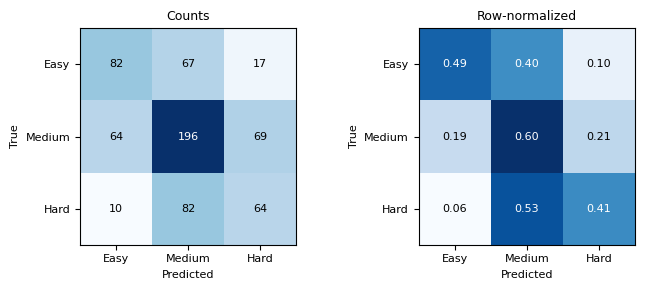

,precision,recall,f1,support
Easy,0.526,0.494,0.509,166
Medium,0.568,0.596,0.582,329
Hard,0.427,0.410,0.418,156


In [11]:
best_key = f"{best_cv['rep']}_{best_cv['model']}"
P_best = np.load(os.path.join(PROBA_DIR, f'{best_key}_test.npy'))
pred_best = P_best.argmax(axis=1)

cm = confusion_matrix(yte, pred_best, labels=[0, 1, 2])
cm_norm = cm / cm.sum(axis=1, keepdims=True)
pd.DataFrame(cm, index=[f'true_{c}' for c in CLASS_NAMES],
             columns=[f'pred_{c}' for c in CLASS_NAMES]).to_csv(os.path.join(TAB_DIR, 'difficulty_confusion_best.csv'))
pd.DataFrame(cm_norm.round(3), index=[f'true_{c}' for c in CLASS_NAMES],
             columns=[f'pred_{c}' for c in CLASS_NAMES]).to_csv(os.path.join(TAB_DIR, 'difficulty_confusion_best_norm.csv'))

errors = cm.sum() - np.trace(cm)
far = cm[0, 2] + cm[2, 0]
print('Model terbaik (CV):', best_key)
print(cm)
print('Proporsi kesalahan Easy<->Hard :', round(far / errors * 100, 1), '%')
print('Proporsi kesalahan yang melibatkan Medium:', round((cm[1].sum() - cm[1, 1] + cm[:, 1].sum() - cm[1, 1]) / errors * 100, 1), '%')
print('Distribusi prediksi:', dict(zip(CLASS_NAMES, np.bincount(pred_best, minlength=3))),
      '| distribusi asli:', dict(zip(CLASS_NAMES, np.bincount(yte, minlength=3))))

fig, axes = plt.subplots(1, 2, figsize=(7, 3))
for ax, mat, title, fmt in [(axes[0], cm, 'Counts', '{:d}'), (axes[1], cm_norm, 'Row-normalized', '{:.2f}')]:
    ax.imshow(mat, cmap='Blues')
    ax.set_xticks(range(3)); ax.set_xticklabels(CLASS_NAMES, fontsize=8)
    ax.set_yticks(range(3)); ax.set_yticklabels(CLASS_NAMES, fontsize=8)
    ax.set_xlabel('Predicted', fontsize=8); ax.set_ylabel('True', fontsize=8)
    ax.set_title(title, fontsize=9)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, fmt.format(mat[i, j]), ha='center', va='center', fontsize=8,
                    color='white' if mat[i, j] > mat.max() * 0.6 else 'black')
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, 'difficulty_confusion_best.png'), dpi=300, bbox_inches='tight')
plt.show()

prec, rec, f1c, sup = precision_recall_fscore_support(yte, pred_best, labels=[0, 1, 2], zero_division=0)
per_class = pd.DataFrame({'precision': prec, 'recall': rec, 'f1': f1c, 'support': sup},
                         index=CLASS_NAMES).round(3)
per_class.to_csv(os.path.join(TAB_DIR, 'difficulty_per_class_best.csv'))
per_class

## Ringkasan untuk paper

Salin dari notebook ini: (1) tabel penuh Accuracy / Precision / Recall / F1 (`difficulty_table_full.csv`), (2) dua baris baseline, (3) interval bootstrap, (4) confusion matrix model terbaik dan per-class F1, (5) proporsi kesalahan Easy↔Hard dan yang melibatkan Medium.

**Untuk RQ4 (topik vs difficulty):** bandingkan selisih terhadap baseline, bukan angka mentah. Misalnya Macro-F1 difficulty berapa poin di atas baseline acak, dibanding Macro-F1 topik di atas baseline acaknya. Jangan menyimpulkan penyebabnya (misalnya "constraints hilang") dari tabel ini saja. Itu dugaan yang baru bisa diuji lewat Notebook 07 (ablasi angka).

Kalau model difficulty hampir tidak berbeda dari baseline acak, itu temuan yang sah dan justru memperkuat pembahasan RQ4.